# Diving deeper into MLPs

Set us up for more complex architectures

### Issues with the current setup

**Logits at Initialisation**: setting up random weights and biases, particularly for the output layer, can yield extreme values for logits. This means that for the first batches of gradient descent, our model has to make some large gains and fix the instability by essentially squashing these logits back to smaller values. This is why we get the hockey stick effect when plotting iterations vs loss. However, if we squash the logits ourselves (by setting our biases to 0 and weights to close to 0), the model starts at a reasonable loss, and can spend more time actually optimising rather than stabilising

**Activations in the hidden layer at intialisation**: Many of the activations in the first hidden layer also have extreme values when intialised with random weights and biases. This means when they pass through the tanh activation function, you get a histogram that looks like |....| with all of the values concentrated at -1 and 1. This is disastrous because, recall when we do backpropagation, the gradient of the tanh activation is (local gradient: 1-tanh**2) * (gradient of subsequent node). So when tanh is -1 or 1, the local gradient goes to 0, effectively wiping out the gradient from that node and stopping the backpropagation in its tracks, with the 0 from that node continuing to flow on backward. The model will know that there is not much point in changing the weights and biases for that node, since the tanh will squash it to 1 or -1 anyway, so those nodes effectively don't get trained

Conversely, we dont want our linear activations (x @ w + b) to be too squashed and centred around 0, otherwise tanh wont be doing anything

Good practices for neural net training
- view gradient plots (histograms etc)
- view activations (histograms)


This example, with only one hidden layer, is quite forgiving. Relatively small amount of parameters mean that its able to train and optimise well enough regardless of initialisation. 

Previously, the initialisation of neural nets was quite important, but now due to innovations and new algorithms, it has become easier and more reliable without having to spend too much time perfecting the initialisation

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [7]:
# Start with our previous MLP
words = open('names.txt', 'r').read().splitlines()
chars = sorted(list(set(''.join(words))))
s_to_i = {s: i+1 for i, s in enumerate(chars)}
s_to_i['.'] = 0
i_to_s = {i:s for s, i in s_to_i.items()}

In [8]:
block_size = 3

# create the dataset, now we have 228146 datapoints
# implement test and training splits
def build_dataset(words):
    X, Y = [], []

    for w in words:
        context = [0] * block_size
        for ch in w+'.':
            ix = s_to_i[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words)) # set first split point for train vs test/val
n2 = int(0.9*len(words)) # second split point for  test vs val

# create the datasets
X_train, Y_train = build_dataset(words[:n1])
X_val, Y_val = build_dataset(words[n1:n2])
X_test, Y_test = build_dataset(words[n2:])

In [ ]:
'''emb_dim = 10
hidden_layer_size = 200

# initialise
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, emb_dim),                              generator=g)
W1 = torch.randn((emb_dim * block_size, hidden_layer_size), generator=g) * 0.15 # same thing as below for the first weights and biases too, to fix the tanh imbalance with our hidden activations
b1 = torch.randn(hidden_layer_size,                         generator=g) * 0.01
W2 = torch.randn((hidden_layer_size, 27),                   generator=g) * 0.01 # we shrink the final weights to something very small (not 0) - this flattens out our logits, meaning we get a much more stable loss initially
b2 = torch.randn(27,                                        generator=g) * 0 # we also start with 0 bias for the same effect as above
params = [C, W1, b1, W2, b2]

for p in params:
    p.requires_grad = True'''

In [5]:
# however, the above multiplications can be tuned in a better way rather than just guessing and trying to get them close to 0
# randn samples from standard normal (mean 0, stddev 1), but when we multiply with datapoints x (often also standard normal encodings), the standard deviation often blows out
# x = torch.randn(10, 100)
# w = torch.randn(100, 10)
# y = x @ w
# print(x.mean(), x.std())
# print(y.mean(), y.std()) # originally notice how this ends up being around 10 - this means that the linear activations end up also being extreme, and causes the tanh to concentrate at -1 and 1

x = torch.randn(10, 100)
w = torch.randn(100, 10) / 100**0.5 # where 100 is known as the fan in
y = x @ w
print(x.mean(), x.std())
print(y.mean(), y.std()) # now the std dev is around 1 which matches x

# this is automatically implemented with torch.nn.init.kaiming_normal_
# quick note: the simple sqrt(fan_in) only applies to tanh, other nonlinearities need slightly different scalars


tensor(-0.0422) tensor(1.0210)
tensor(-0.0635) tensor(1.0232)


In [9]:
emb_dim = 10
hidden_layer_size = 200

# initialise
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, emb_dim),                              generator=g)
W1 = torch.randn((emb_dim * block_size, hidden_layer_size), generator=g) * (5/3) / (emb_dim * block_size)**0.5 # using the kaiming normal, we multiply by 5/3 (gain for tanh)/sqrt(fan in) (number of inputs)
b1 = torch.randn(hidden_layer_size,                         generator=g) * 0.01
W2 = torch.randn((hidden_layer_size, 27),                   generator=g) * (5/3) / (hidden_layer_size)**0.5
b2 = torch.randn(27,                                        generator=g) * 0
params = [C, W1, b1, W2, b2]
for p in params:
    p.requires_grad = True

In [10]:
iterations = 200000 
batch_size = 32
lossi = []

for k in range(iterations):

    # set up minibatching
    ix = torch.randint(0, X_train.shape[0], (batch_size, )) # generate n integers from 0 to the length of X to give us the index that will make up our batches for training
    Xb, Yb = X_train[ix], Y_train[ix]

    # forward
    emb = C[Xb]
    emb_cat = emb.view(emb.shape[0], -1)
    hidden_activation = torch.tanh(emb_cat @ W1 + b1)
    logits = hidden_activation @ W2 + b2
    loss = F.cross_entropy(logits, Yb)
    
    # backward
    for p in params: # flush
        p.grad = None
    loss.backward()

    # gradient descent
    lr = 0.1 if k < 100000 else 0.01
    for p in params:
        p.data += -lr * p.grad

    if k % 10000 == 0:
        print(f'{k:7d}/{iterations:7d}: {loss.item():.4f}')


      0/ 200000: 4.5257
  10000/ 200000: 2.1374
  20000/ 200000: 2.4461
  30000/ 200000: 2.2224
  40000/ 200000: 2.2685
  50000/ 200000: 2.2859
  60000/ 200000: 2.1254
  70000/ 200000: 1.5522
  80000/ 200000: 1.7007
  90000/ 200000: 1.9368
 100000/ 200000: 2.3766
 110000/ 200000: 1.8026
 120000/ 200000: 1.8858
 130000/ 200000: 2.0040
 140000/ 200000: 2.0040
 150000/ 200000: 1.9189
 160000/ 200000: 2.1872
 170000/ 200000: 1.9311
 180000/ 200000: 1.8656
 190000/ 200000: 1.8507


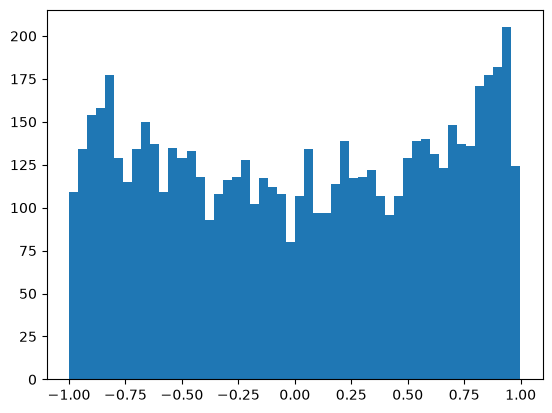

In [ ]:
# quick viz to show the |....| distribution of h without proper initialisation
h = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)
plt.hist(h.view(-1).tolist(), bins=50);

In [11]:
def show_split_loss(split):
    x, y = {
        'train': (X_train, Y_train),
        'val': (X_val, Y_val),
        'test': (X_test, Y_test)
    }[split]

    emb = C[x]
    h = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

show_split_loss('train')
show_split_loss('val')

train 2.039294719696045
val 2.107470750808716


# Batch Normalisation

From our findings above, at initialisation we want our linear activations (x @ w + b) to be roughly standard normal since this will ensure stable nonlinear activations (relu, tanh etc). Batch normalisation proposes that instead of worrying about our setup, why don't we just sample from the standard normal curve anyway by normalising the data (subtract mean, divide std dev)